# 10 系统聚类和 K 均值聚类

> **模块**：多元分析 ｜ **数据**：`basketball.csv` ｜ **依赖**：numpy、pandas、matplotlib、scipy、scikit-learn

## 1. 问题背景

聚类分析是一类将数据所对应的研究对象进行分类的统计方法。这一类方法的共同特点是，事先不知道类别的个数与结构，进行分析的数据是表明对象之间的相似性或相异性的数据，将这些数据看成对对象“距离”远近的一种度量，将距离近的对象归入一类。不同类对象之间的距离较远。


## 2. 学习目标

- 掌握常用的样本距离和相似系数
- 掌握系统聚类的基本方法
- 掌握 K 均值聚类的方法


## 3. 环境与数据

- Jupyter 开发环境
- Python 3.10


## 4. 方法与实现

### 4.1 距离和相似系数

设有$n$个样本，每个样本测得$p$项指标（变量），原始数据矩阵为：

$$
A = \{(a_{ij})\}_{n×p}=\begin{bmatrix}
a_{11} & a_{12} & \cdots & a_{1p} \\
a_{21} & a_{22} & \cdots & a_{2p} \\
\vdots & \vdots & \ddots & \vdots \\
a_{n1} & a_{n2} & \cdots & a_{np}
\end{bmatrix}

$$

其中$a_{ij}$为第$i$个样本的第$j$个指标的观测数据。

研究样本的亲疏程度或相似程度的数量指标通常有两种：

- **相似系数**：性质越接近的样本，其取值越接近于1或-1，而彼此无关的样本相似系数则接近于0，相似的归为一类，不相似的归为不同类。
- **距离**：它将每个样本看成$p$维空间的一个点，$n$个样本组成$p$维空间的$n$个点。用各点之间的距离来衡量各样本之间的相似程度。距离近的点归为一类，距离远的点属于不同的类。

#### 4.1.1 距离

设$d_{ij}$表示第$i$个样本与第$j$个样本的距离，常用的距离有以下几种：

1. **曼哈顿距离**（绝对距离）：$d_{ij} = \sum_{k=1}^{p}{|a_{ik}-a_{jk}|}$
2. **欧式距离**：$d_{ij} = \sqrt{\sum_{k=1}^{p}{(a_{ik}-a_{jk})}^2}$
3. **切比雪夫距离**（最大距离）：$d_{ij} = \underset{1≤k≤p}{max}{|a_{ik}-a_{jk}|}$
4. **马氏距离**：$d_{ij} = \sqrt{(A_i-A_j)Σ^{-1}{(A_i-A_j)}^T}$

其中$A_i$表示$A$矩阵的第$i$行，$Σ$表示观测变量之间的协方差矩阵。

**表1**: 样本的距离矩阵（绝对值距离）

|   | 1 | 2 | 5 | 9 | 13 |
|---|---|---|---|---|----|
| 1 | 0 | 1 | 4 | 8  | 12 |
| 2 | 1 | 0 | 3 | 7  | 11 |
| 5 | 4 | 3 | 0 | 4  | 8  |
| 9 | 8 | 7 | 4 | 0  | 4  |
| 13| 12| 11| 8 | 4  | 0  |

> *原稿配图未随 notebook 保存，此处暂缺。*

使用`scipy`库`spatial`下的`distance`子模块可以计算距离：

```python
scipy.spatial.distance.pdist(X, metric='euclidean', p=2, w=None, V=None, VI=None)

```


In [1]:
import numpy as np
import pandas as pd
from scipy import spatial
# 放入五个样本的数据
data = np.array([[1,2,5,9,13]])
# 计算n维空间中观测值之间的距离
# pdist(X, metric='euclidean')
# X表示需要计算距离的数据；metric表示计算距离的方法，'cityblock'表示绝对值距离。
dist1 = spatial.distance.pdist(data.T,'cityblock')
print('绝对值距离矩阵为：\n', dist1) 

绝对值距离矩阵为：
 [ 1.  4.  8. 12.  3.  7. 11.  4.  8.  4.]


**例2**. 某篮球联赛共计256名篮球运动员，下表展示了他们的赛季场均得分（PPG）、场均篮板（RPG）和场均助攻（ARG）的前10条记录，整体数据保存在 `./experiment/data/basketball.csv` 文件中（不含表头），试采用夹角余弦度量每个球员之间的相似度。

| 球员 | PPG | RPG | ARG |
| ---- | --- | --- | --- |
| 1    | 25.3 | 5.2 | 7.8 |
| 2    | 22.1 | 7.0 | 5.4 |
| 3    | 20.9 | 4.3 | 8.0 |
| 4    | 19.5 | 6.1 | 6.2 |
| 5    | 18.7 | 5.5 | 4.9 |
| 6    | 16.8 | 7.2 | 8.5 |
| 7    | 15.0 | 6.5 | 5.0 |
| 8    | 14.2 | 5.0 | 7.5 |
| 9    | 12.8 | 4.1 | 3.9 |
| 10   | 10.5 | 3.7 | 2.6 |

接下来，使用夹角余弦来计算每个球员之间的相似度。

In [2]:
import pandas as pd
from scipy.spatial.distance import cosine

data = pd.read_csv('../data/basketball.csv', header=None)
scores = data.values
# 计算夹角余弦相似度
sm = 1 - pd.DataFrame([[cosine(scores[i], scores[j]) for j in range(len(scores))] for i in range(len(scores))])
print(sm) # 输出相似度矩阵similarity_matrix 

          0         1         2         3         4         5         6    \
0    1.000000  0.912159  0.794452  0.840013  0.551272  0.919113  0.955768   
1    0.912159  1.000000  0.934938  0.985749  0.273201  0.999709  0.983525   
2    0.794452  0.934938  1.000000  0.970256  0.351362  0.937514  0.935068   
3    0.840013  0.985749  0.970256  1.000000  0.216373  0.984344  0.958412   
4    0.551272  0.273201  0.351362  0.216373  1.000000  0.296293  0.442452   
..        ...       ...       ...       ...       ...       ...       ...   
251  0.987637  0.903328  0.736785  0.819285  0.444282  0.907517  0.928272   
252  0.866232  0.987164  0.979073  0.996914  0.292320  0.987650  0.973998   
253  0.844944  0.986453  0.972152  0.999910  0.229464  0.985371  0.961528   
254  0.903472  0.996556  0.907058  0.977235  0.211715  0.994679  0.969163   
255  0.960860  0.797351  0.728910  0.720926  0.760695  0.810433  0.887704   

          7         8         9    ...       246       247       248  \
0  

In [3]:
ball = np.loadtxt('../data/basketball.csv', delimiter= ',') 
# metric='cosine'表示计算夹角余弦。
dist2 = spatial.distance.pdist(ball,'cosine')
print('每个变量之间的相似度为：\n', dist2)

每个变量之间的相似度为：
 [0.08784095 0.20554827 0.15998659 ... 0.0228912  0.27088262 0.22936317]


### 4.2 系统聚类

系统聚类法也称为层次聚类法，其基本思想为：开始时将n个样本各自为一类，并规定样本之间的距离和类与类之间的距离，然后将距离最近的两类合并成一个新类，再计算新类与其他类的距离；重复进行两个最近类的合并，每次减少一类，直至所有样本合并成一类。具体步骤如下：

1. 将每个样本独立聚成一类，构造n个类。
2. 根据所确定的样本距离公式，计算n个样本（或变量）两两的距离，构造距离矩阵，记为 $D_{(0)}$。
3. 把距离最近的两类归为一个新类，其他样本仍各自聚为一类，共聚成n-1类。
4. 计算新类与当前各类的距离，将距离最近的两个类进一步聚成一类，共聚成n-2类。以上步骤一直进行下去，最后将所有的样本聚成一类。
5. 画聚类谱系图。
6. 确定类的个数及各类包含的样本数，并对类做出解释。

正如样本之间的距离可以有不同的定义方法，类与类之间的距离也有各种定义。类与类之间用不同的方法定义距离，就产生了不同的系统聚类方法，本次实验介绍两种常用的方法。

#### 4.2.1 最短距离法

设 $G_1, G_2, ..., G_n$ 表示类。

最短距离法具体步骤如下：

1. 定义样本之间的距离，计算n个样本的距离矩阵 $D_{(0)}$（对称矩阵）。
2. 找出 $D_{(0)}$ 的非对角线最小元素，设为 $D_{KL}$，则将 $G_K$ 和 $G_L$ 合并成一个新类，记为 $G_M$，即 $G_M = G_K \cup G_L$。
3. 计算新类与任一类 $G_J$ 的距离公式：$$D_{MJ} = \min\{D_{KJ}, D_{MJ}\}$$。在 $D_{(0)}$ 中 $G_K$ 和 $G_L$ 所在的行和列，合并成一个新行及新列，对应 $G_M$，该行及该列上的新距离由上式求得，其余行列上的距离值不变。这样就得到新的距离矩阵，记为 $D_{(1)}$。
4. 对 $D_{(1)}$ 重复第2步和第3步得到 $D_{(2)}$，直至所有元素合并成一类为止。

例3.1991年辽宁等5省城镇居民月均消费数据（单位：元/人）如下表：

> *原稿配图未随 notebook 保存，此处暂缺。*

#### 4.2.2 变量解释

- $x_1$ ：人均粮食支出
- $x_2$ ：人均衣着商品支出
- $x_3$ ：人均副食支出
- $x_4$ ：人均日用品支出
- $x_5$ ：人均烟、酒、茶支出
- $x_6$ ：人均燃料支出
- $x_7$ ：人均其他副食支出
- $x_8$ ：人均非商品支出

#### 4.2.3 系统聚类：最短距离法

采用最短距离法对5个省份进行聚类。使用`scipy`库中的`cluster`模块的`hierarchy`子模块，可以实现系统聚类。使用该子模块下的`linkage`函数可以实现最短距离法、最长距离法、类平均法和重心法等。


[[ 2.          3.          2.2032703   2.        ]
 [ 4.          5.          2.21585198  3.        ]
 [ 0.          1.         11.68997006  2.        ]
 [ 6.          7.         12.80957064  5.        ]]


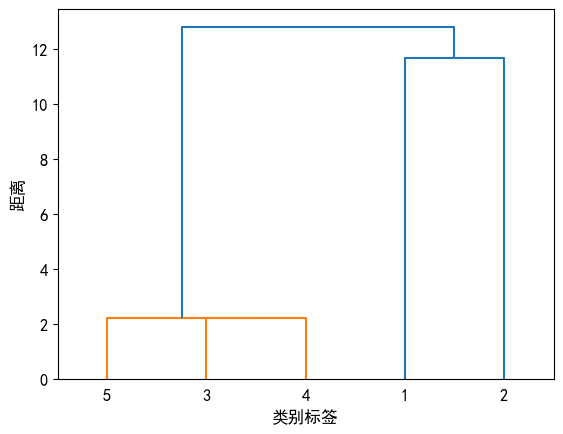

In [4]:
import scipy.cluster.hierarchy as sch
import matplotlib.pyplot as plt
# 用来正常显示中文标签
plt.rcParams['font.sans-serif']=['SimHei'] 
# 正常显示负号
plt.rc('axes',unicode_minus=False)
# 定义数据
a = np.array([[7.9,39.77,8.42,12.94,19.27,11.05,2.04,13.29],[7.68,50.37,11.35,13.3,19.25,14.59,2.75,14.87],
            [9.42,27.93,8.2,8.14,16.17,9.42,1.55,9.76],[9.16,27.98,9.01,9.32,15.99,9.1,1.82,11.35],
            [10.06,28.64,10.52,10.05,16.18,8.39,1.96,10.81]])
# 方法一：先求样本之间的距离再聚类
dist = sch.distance.pdist(a)
MIN = sch.linkage(dist,method='single')

# 方法二：直接放入数据求最短距离结果
MIN = sch.linkage(a,method='single')
# 显示返回值
print(MIN)

#画聚类图
plt.rc('font',size=12)
s=np.arange(1,6)
# 绘制层次聚类图
sch.dendrogram(MIN,labels=s)
plt.xlabel('类别标签')
plt.ylabel('距离')
plt.show()

将每个省份看成一个样本，并以1,2,3,4,5分别表示辽宁、浙江、河南、甘肃、青海5个省，计算两组间的欧式距离$d_{ij}(i,j=1,2,3,4,5)$
- （1）首先，将5个省看各一类，即令$G_i = \{i\}(i=1,2,3,4,5),mind_{ij} = d_{34}=2.20$，所以将$G_3$和$G_4$在水平2.20上合并成一个新类$G_6 = \{3,4\}$
- （2）$mind_{ij}(i,j=1,2,5,6) = d_{56}=2.21$，所以合成一个新类$G_7 = \{3,4,5\}$
- （3）$mind_{ij}(i,j=1,2,7) = d_{12}=11.68$，所以合成一个新类$G_8 = \{1,2\}$
- （4）$mind_{78}=12.8$，$G_9 = \{1,2,3,4,5\}$，这时五个样本聚为一类，过程终止。

#### 4.2.4 最长距离法

最长距离法与最短距离法的合并步骤完全一样，只是类与类之间的定义和计算新类与其他类的距离所用的公式不同。

[[ 2.          3.          2.2032703   2.        ]
 [ 4.          5.          3.50368378  3.        ]
 [ 0.          1.         11.68997006  2.        ]
 [ 6.          7.         24.63527349  5.        ]]


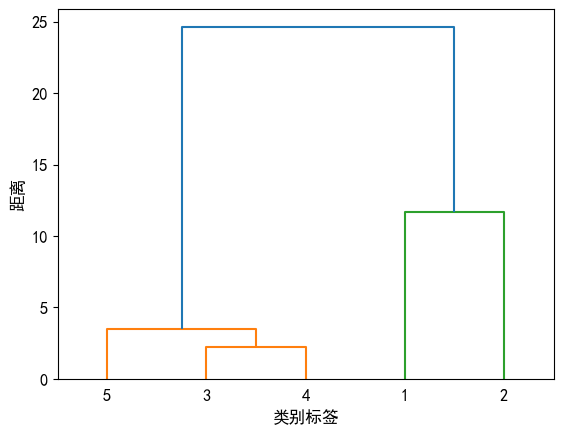

In [5]:
dist = sch.distance.pdist(a)
MAX = sch.linkage(dist,method='complete')
# 显示返回值
print(MAX)

#画聚类图
plt.rc('font',size=12)
s=np.arange(1,6)
sch.dendrogram(MAX,labels=s)
plt.xlabel('类别标签')
plt.ylabel('距离')
plt.show()

将每个省份看成一个样本，并以1,2,3,4,5分别表示辽宁、浙江、河南、甘肃、青海5个省，计算两组间的欧式距离$d_{ij}(i,j=1,2,3,4,5)$
- （1）先将$G_3$和$G_4$在水平2.20上合并成一个新类$G_6 = \{3,4\}$
- （2）设最长距离为$D(G_i,G_j)$(例如$D(G_6,G_i) = max(d_{3i},d_{4i})$)$minD_{ij}(i,j=1,2,5,6,i≠j) = D(G_6,G_5)=3.51$，所以合成一个新类$G_7 = \{3,4,5\}$
- （3）$minD(G_i,G_j)(i,j=1,2,7,i≠j) = D(G_1,G_2)=11.68$，所以合成一个新类$G_8 = \{1,2\}$
- （4）$min(G_7,G_8)=24.63$，$G_9 = \{1,2,3,4,5\}$，这时五个样本聚为一类，过程终止。

### 4.3 K 均值聚类

使用层次聚类法聚类时，随着聚类样本对象的增多，计算量会迅速增加，而且聚类结果——谱系图会十分复杂，不便于分析。为了改进上述缺点，一个自然的想法是先粗略地分一下类，然后按某种最优原则进行修正，直到将类分得比较合理为止，基于这种思想就产生了动态聚类法，也称逐步聚类法。

动态聚类法适用于大型数据，动态聚类法有许多种方法，本次实验介绍一种比较流行的动态聚类法——K均值聚类法。

K均值聚类基本步骤如下：
1. 从n个样本数据中随机选取k个对象作为初始的聚类中心
2. 分别计算每个样本到各个聚类质心的距离，将样本分配到距离最近的那个聚类中心类别中
3. 所有样本分配完成后，重新计算k个聚类的中心
4. 与前一次计算得到的k个聚类中心比较，如果聚类中心发生变化，转第二步，否则转第五步
5. 当中心不再发生变化时，停止并输出聚类结果。

例2续.某篮球联赛共计256名篮球运动员，有他们的赛季场均得分（PPG）、场均篮板（RPG）和场均助攻（ARG）数据。试采用K均值聚类法对球员进行聚类。聚类簇数k由轮廓系数法确定。

#### 4.3.1 确定簇数值

对于K均值聚类来说，如何确定簇数k值是一个至关重要的问题。通常会使用簇内离差平方和拐点法和轮廓系数法。

轮廓系数法综合考虑了簇的密集性与分散性两个信息，如果数据集被分割为理想的k个簇，那么对应的簇内样本会很密集，而簇间样本会很分散。

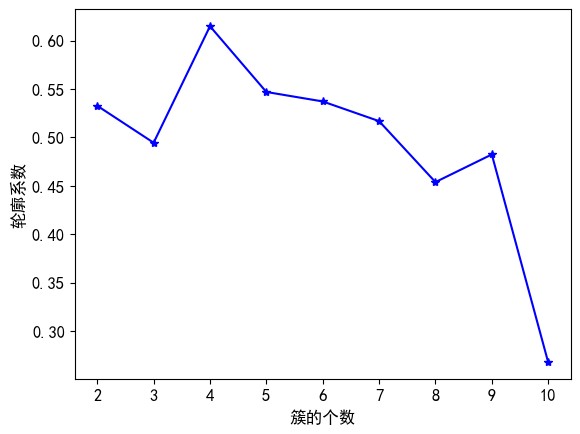

In [6]:
from sklearn.cluster import KMeans
from sklearn import metrics
ball=np.loadtxt('../data/basketball.csv', delimiter= ',')
S=[]
K=10
# 轮廓系数法接受的聚类簇数必须大于等于2
for k in range(2,K+1):
    md = KMeans(k)
    md.fit(ball)
    labels = md.labels_
    # 计算轮廓系数
    # silhouette_score(X, labels, metric='euclidean',...)
    # X表示需要计算的数据；labels表示数据标签；metric表距离的计算方法，默认为欧式距离法
    S.append(metrics.silhouette_score(ball,labels,metric='euclidean'))  
# 画图
plt.rc('font',size=12)
# 用来正常显示中文标签
plt.rc('font',family='SimHei')
plt.plot(range(2,K+1), S, 'b*-')
plt.xlabel('簇的个数')
plt.ylabel('轮廓系数')
plt.show()

当k等于4时，轮廓系数最大，且比较接近于1.说明应该把数据聚为四类比较合理。

#### 4.3.2 K 均值法聚类

在做K均值聚类时需要注意两点，一个是聚类前必须指定具体的簇数k值，另一个是对原始数据集做必要的标准化处理。

由于K均值思想是基于点之间的距离实现“物以类聚”的，所以如果原始数据集存在量纲上的差异，就必须对其进行标准化的预处理。

聚类中心为：
 [[ 0.18406378  1.38727916 -0.52816053]
 [ 0.24347994 -0.37418873  1.66790201]
 [ 1.28725407 -0.65793748 -0.49221259]
 [-1.40579811 -0.69128934 -0.53727836]]


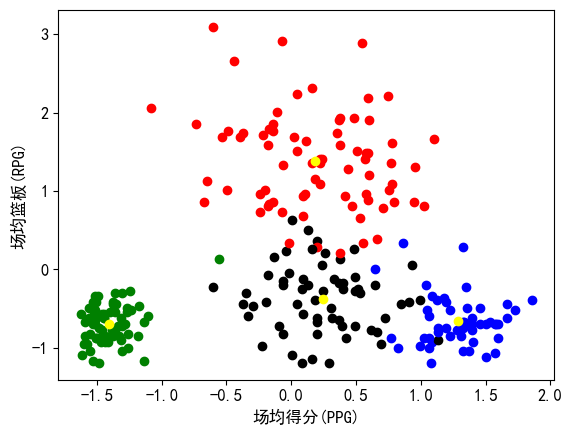

In [7]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import scale
# 对数据进行单位化
a = scale(ball)
# 构建K-Means模型，簇数为4
md = KMeans(4)
# 训练模型
md.fit(a)  
# 获取聚类标签
labels=md.labels_ 
# 获取聚类中心
centers=md.cluster_centers_
print('聚类中心为：\n',centers)
# 为数据添加标签列
b = np.column_stack((a,labels))

# 画图
# 用来正常显示中文标签
plt.rc('font',family='SimHei')
# 设置字体大小
plt.rc('font',size=12)

# 画出单位化后数据和聚类中心的散点图
str = ['red','black','blue','green']
for i in range(len(b)):
    for j in range(4):
        if int(b[:,-1][i])==j:
            plt.scatter(a[i,0],a[i,1],color=str[j])
plt.scatter(centers[:,0],centers[:,1],color='yellow')
plt.xlabel('场均得分(PPG)')
plt.ylabel('场均篮板(RPG)')
plt.show()

### 4.4 Q 型聚类与树状图

> 来源：教材参考实现《数学建模算法与应用》10.1 节的练习稿（MIT，Zhanghan Wang），代码保持原样，仅按需改写数据路径并清空输出。

#### 1.Q型聚类分析: 对样本进行分类
1. 样本相似性度量  
Mahalanobis距离(马氏距离). 对一切线性变换均不变.
2. 类间相似性度量  
最短/长距离法, 重心法, 类平均法, 离差平方和法(Ward方法)
3. 聚类图(树形图/树状图)  
聚类图怎么看: https://jingyan.baidu.com/article/29697b9109d147ab21de3c44.html.

#### 2.R型聚类分析: 对变量进行分类
1. 变量相似性度量  
应满足: I.相关系数 <= 1; II.具有交换性; III.越接近1表示越相似
    - 相关系数及相关系数矩阵  
    - 夹角余弦

2. 变量聚类法(224页): 列出相关系数矩阵后,可以使用聚类图的方法直观表示.
    - 最长距离法
    - 最短距离法

In [8]:
import numpy as np
import matplotlib.pyplot as plt

{'icoord': [[15.0, 15.0, 25.0, 25.0],
  [35.0, 35.0, 45.0, 45.0],
  [20.0, 20.0, 40.0, 40.0],
  [5.0, 5.0, 30.0, 30.0]],
 'dcoord': [[0.0, 1.0, 1.0, 0.0],
  [0.0, 2.0, 2.0, 0.0],
  [1.0, 3.0, 3.0, 2.0],
  [0.0, 4.0, 4.0, 3.0]],
 'ivl': ['4', '0', '1', '2', '3'],
 'leaves': [4, 0, 1, 2, 3],
 'color_list': ['C1', 'C2', 'C0', 'C0'],
 'leaves_color_list': ['C0', 'C1', 'C1', 'C2', 'C2']}

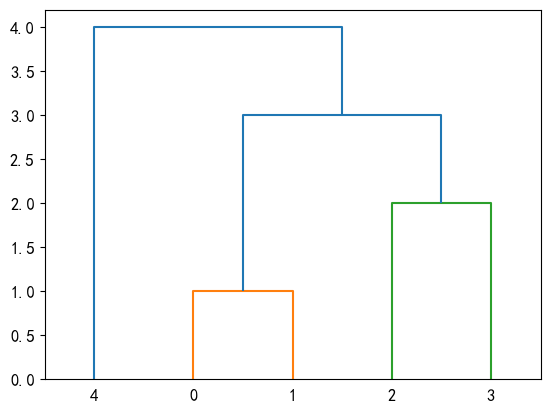

In [9]:
# scikit-learn 没有绘制树状图的功能，需借助 SciPy 库完成
from scipy.cluster.hierarchy import dendrogram, ward, linkage
from sklearn.datasets import make_blobs
import matplotlib.pyplot as plt

# method是类间距求法. 'single':以最小距离为间距
# 关于metric的有效值,可参照《数学建模算法与应用（第二版）》的222页
dendrogram(linkage(
    [[1,0],
     [1,1],
     [3,2],
     [4,3],
     [2,5]], method='single', metric='cityblock'))

[ 1.         11.          0.40652755  2.        ]	1.0与11.0聚成类2.0, 高0.4065275519288681
[ 5.         13.          0.85780833  3.        ]	5.0与13.0聚成类3.0, 高0.8578083327495438
[ 0.         12.          0.97563165  2.        ]	0.0与12.0聚成类2.0, 高0.975631650073492
[6.         9.         1.00830799 2.        ]	6.0与9.0聚成类2.0, 高1.0083079879584977
[ 3.         16.          1.61021529  3.        ]	3.0与16.0聚成类3.0, 高1.610215288701898
[ 2.         15.          2.11460258  3.        ]	2.0与15.0聚成类3.0, 高2.114602581526248
[ 4.         14.          2.19814438  4.        ]	4.0与14.0聚成类4.0, 高2.1981443759799824
[ 7.         17.          2.55140319  4.        ]	7.0与17.0聚成类4.0, 高2.551403190505968
[10.         18.          2.66056688  4.        ]	10.0与18.0聚成类4.0, 高2.6605668783953114
[ 8.         20.          3.25828581  5.        ]	8.0与20.0聚成类5.0, 高3.2582858108357935
[21.         22.         21.79812099  9.        ]	21.0与22.0聚成类9.0, 高21.798120991286247
[19.         23.         33.66664764 13.        ]	19.0与23.0聚成

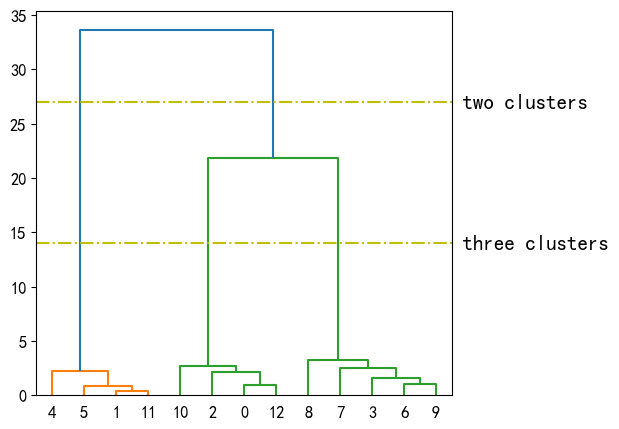

In [10]:
# scikit-learn 没有绘制树状图的功能，需借助 SciPy 库完成
from scipy.cluster.hierarchy import dendrogram, ward
from sklearn.datasets import make_blobs
import matplotlib.pyplot as plt

# 生成模拟数据
X, y = make_blobs(n_samples=13, random_state=42)
# 在数据组 X 上应用 ward 聚类函数，返回聚类过程中所跨越距离的数组
linkage_array = ward(X)
for c in linkage_array:
    print(c, '{}与{}聚成类{}, 高{}'.format(c[0], c[1], c[3], c[2]), sep='\t')
# 绘制树状图
dendrogram(linkage_array)
 
# 标记数中划分为两个和三个簇的位置
ax = plt.gca()
bounds = ax.get_xbound()
plt.plot(bounds, [27, 27], '-.', c='y')
plt.plot(bounds, [14, 14], '-.', c='y')
plt.text(bounds[1], 27, ' two clusters', va='center', fontsize=15)
plt.text(bounds[1], 14, ' three clusters', va='center', fontsize=15)
plt.subplots_adjust(left=0.1, right=0.75, top=0.9, bottom=0.1)
 
plt.show()

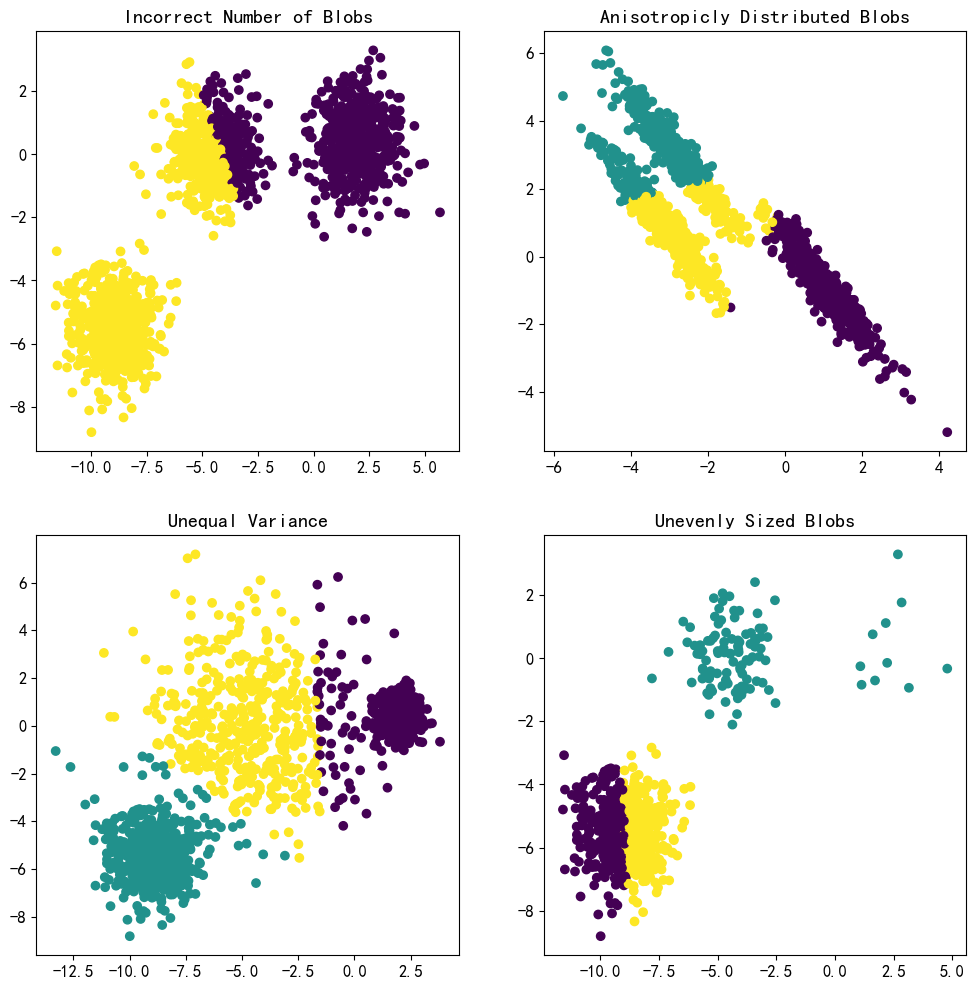

In [11]:
# k-means聚类法示例
# 代码来源: https://scikit-learn.org/stable/auto_examples/cluster/plot_kmeans_assumptions.html#sphx-glr-auto-examples-cluster-plot-kmeans-assumptions-py

import numpy as np
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs

plt.figure(figsize=(12, 12))

n_samples = 1500
random_state = 170
X, y = make_blobs(n_samples=n_samples, random_state=random_state)

# Incorrect number of clusters
y_pred = KMeans(n_clusters=2, random_state=random_state).fit_predict(X)

plt.subplot(221)
plt.scatter(X[:, 0], X[:, 1], c=y_pred)
plt.title("Incorrect Number of Blobs")

# Anisotropicly distributed data
transformation = [[0.60834549, -0.63667341], [-0.40887718, 0.85253229]]
X_aniso = np.dot(X, transformation)
y_pred = KMeans(n_clusters=3, random_state=random_state).fit_predict(X_aniso)

plt.subplot(222)
plt.scatter(X_aniso[:, 0], X_aniso[:, 1], c=y_pred)
plt.title("Anisotropicly Distributed Blobs")

# Different variance
X_varied, y_varied = make_blobs(n_samples=n_samples,
                                cluster_std=[1.0, 2.5, 0.5],
                                random_state=random_state)
y_pred = KMeans(n_clusters=3, random_state=random_state).fit_predict(X_varied)

plt.subplot(223)
plt.scatter(X_varied[:, 0], X_varied[:, 1], c=y_pred)
plt.title("Unequal Variance")

# Unevenly sized blobs
X_filtered = np.vstack((X[y == 0][:500], X[y == 1][:100], X[y == 2][:10]))
y_pred = KMeans(n_clusters=3,
                random_state=random_state).fit_predict(X_filtered)

plt.subplot(224)
plt.scatter(X_filtered[:, 0], X_filtered[:, 1], c=y_pred)
plt.title("Unevenly Sized Blobs")

plt.show()

In [12]:
# 15.7中RBF网络确定中心时使用K-means

import tensorflow as tf
import numpy as np
from matplotlib import pyplot as plt
import numpy as np
from mpl_toolkits.mplot3d import Axes3D
from sklearn.cluster import KMeans
from sklearn import preprocessing

data = np.loadtxt('../data/textbook/15.D 水库年径流与因子特征.txt')
data = preprocessing.scale(data)
trainX = data[:, :-1]
trainY = data[:, -1]

random_state = 170
scores = []
n = 20
for i in range(1, n+1):
    kms = KMeans(n_clusters=i, random_state=None)
    pred = kms.fit_predict(trainX)
    centers = kms.cluster_centers_
    if i == 10:
        print(centers)
    score = 0
    for j in range(trainX.shape[0]):
        score += np.sum(np.square(trainX[j]-centers[pred[j]]))
    scores.append(score)
    

plt.figure()
plt.plot(np.linspace(1, n+1, n), scores)
plt.show()

ModuleNotFoundError: No module named 'tensorflow'

## 5. 小结

本次实验介绍了系统聚类与K均值聚类的思路和一般步骤，实现了基于距离和相似系数、系统聚类、K均值聚类原理的应用以及Python实现。

通过本次实验需要掌握以下内容：
- 掌握常用的样本距离和相似系数
- 掌握系统聚类的基本方法
- 掌握K均值聚类的方法